One way of thinking of HankelDMD is as the fitting of a model $x_{n+1}=F(x_n)$ where
$$F=f^{-1}\circ A\circ f$$
for a particular choice of $f$ and a learned matrix $A$. (In this case $f$ is the formation of the Hankel matrix and then projection onto the PCA components of the Hankel matrix). 

If we fit $n$ training windows of data, we obtain a matrix $A_i$ for each $1\leq i\leq n$. The hypothesis being tested here is that $A_i=J_iDJ_i^{-1}$ for some fixed matrix $D$ of eigenvalues and matrix $J_i$ of eigenvectors where the eigenvector matrices are related by a rotation matrix, $J_i=R_{ij}J_j.$ This would be the case if, say, $J_i=R_iJ$ for some constant matrix $J$ and some rotation matrix $R_i$, since then

$$R_j R_i^{-1} J_i=R_j J=J_j,$$
so that $J_i=(R_jR_i^{-1})^{-1}J_j,$ i.e. $R_{ij}=R_i R_j^{-1}.$

So there are two testable predictions:
1. $D$ is approximately constant.
2. $R_{ij}=J_i J_j^{-1}$ is a rotation matrix, for each $1\leq i,j\leq n.$

In [49]:
import numpy as np
import matplotlib.pylab as plt
from HankelDMD_Predictor import HankelDMD_Predictor as HDMDP
from tqdm.auto import tqdm
from scipy.linalg import polar
import matplotlib.cm as cm
np.set_printoptions(suppress=True,precision=6,linewidth=100000)
plt.rcParams['figure.dpi']=400
SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy')
SV_normalized = SV / np.linalg.norm(SV)
# Fit HankelDMD 100 times
hdmdps = []
k = 9
for n in tqdm(range(100)):
    hdmdps.append(HDMDP(400,k))
    hdmdps[-1].fit(SV_normalized[n*500:(n+1)*500,:50])

  0%|          | 0/100 [00:00<?, ?it/s]

# Consistent Eigenvalues

We first need to sort the eigenvalues/eigenvectors in a consistent way before doing comparisons. We will choose to order the eigenvalues of each fit in ascending order of frequency.

In [50]:
eigs = np.zeros((100,k),dtype='complex128')
evecs = np.zeros((100,k,k),dtype='complex128')
for n in tqdm(range(100)):
    eigs_n,evecs_n = np.linalg.eig(hdmdps[n].A)
    eig_sort_idx = np.argsort(np.imag(np.log(eigs_n)))
    eigs[n] = eigs_n[eig_sort_idx]
    evecs[n] = evecs_n[:,eig_sort_idx]

  0%|          | 0/100 [00:00<?, ?it/s]

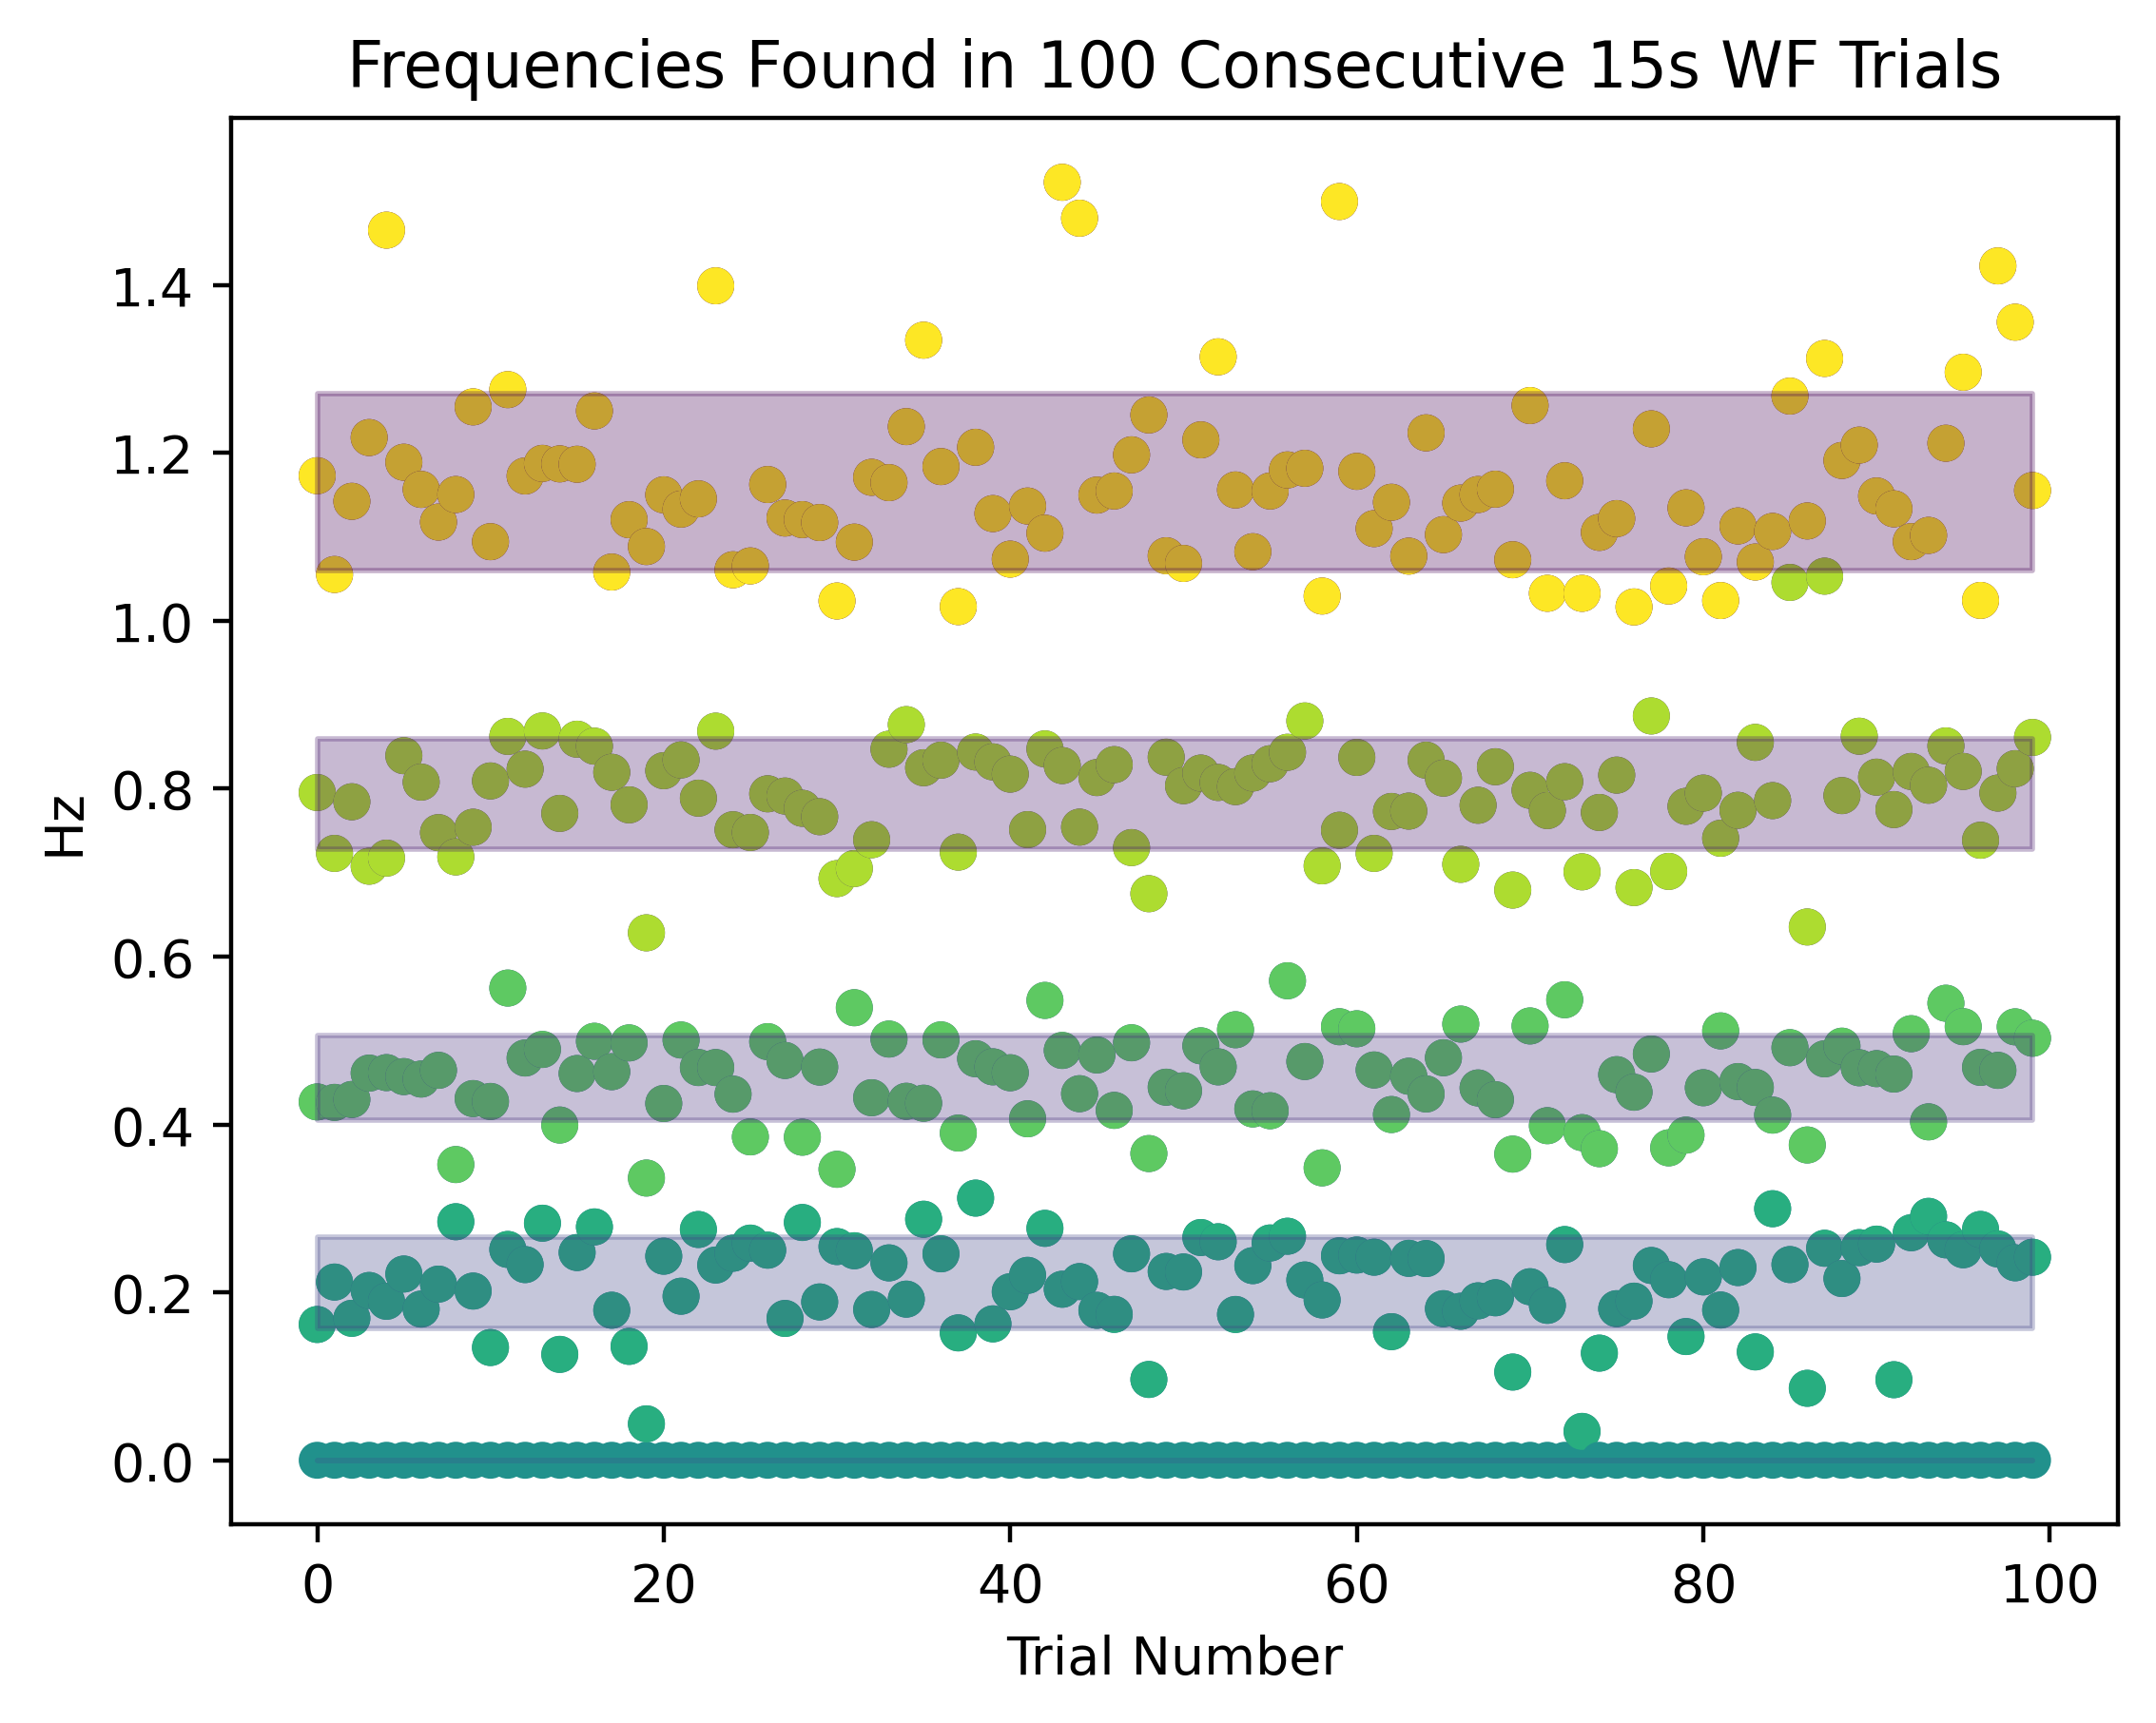

In [51]:
freqs = np.zeros((100,k))
for n in range(100):
    freqs[n] = np.imag(np.log(eigs[n]))/(2*np.pi*0.0285)
mean_freqs = np.mean(freqs,axis=0)
std_freqs = np.std(freqs,axis=0)
sem_freqs = std_freqs / 10
for n in range(100):
    plt.scatter(n*np.ones(k),np.abs(freqs[n]),c=np.arange(k))
    plt.ylabel("Hz")
    plt.xlabel("Trial Number")
    plt.title("Frequencies Found in 100 Consecutive 15s WF Trials")
for i in range(k//2+1):
    plt.fill_between(np.arange(100),np.abs(mean_freqs[i]-std_freqs[i]),np.abs(mean_freqs[i]+std_freqs[i]),alpha=0.3,color=cm.viridis(i/15))
plt.show()

Here each trial corresponds to a 15s of window that we fit. The bands shown are $\pm$ the standard deviation of the frequencies at that frequency level.

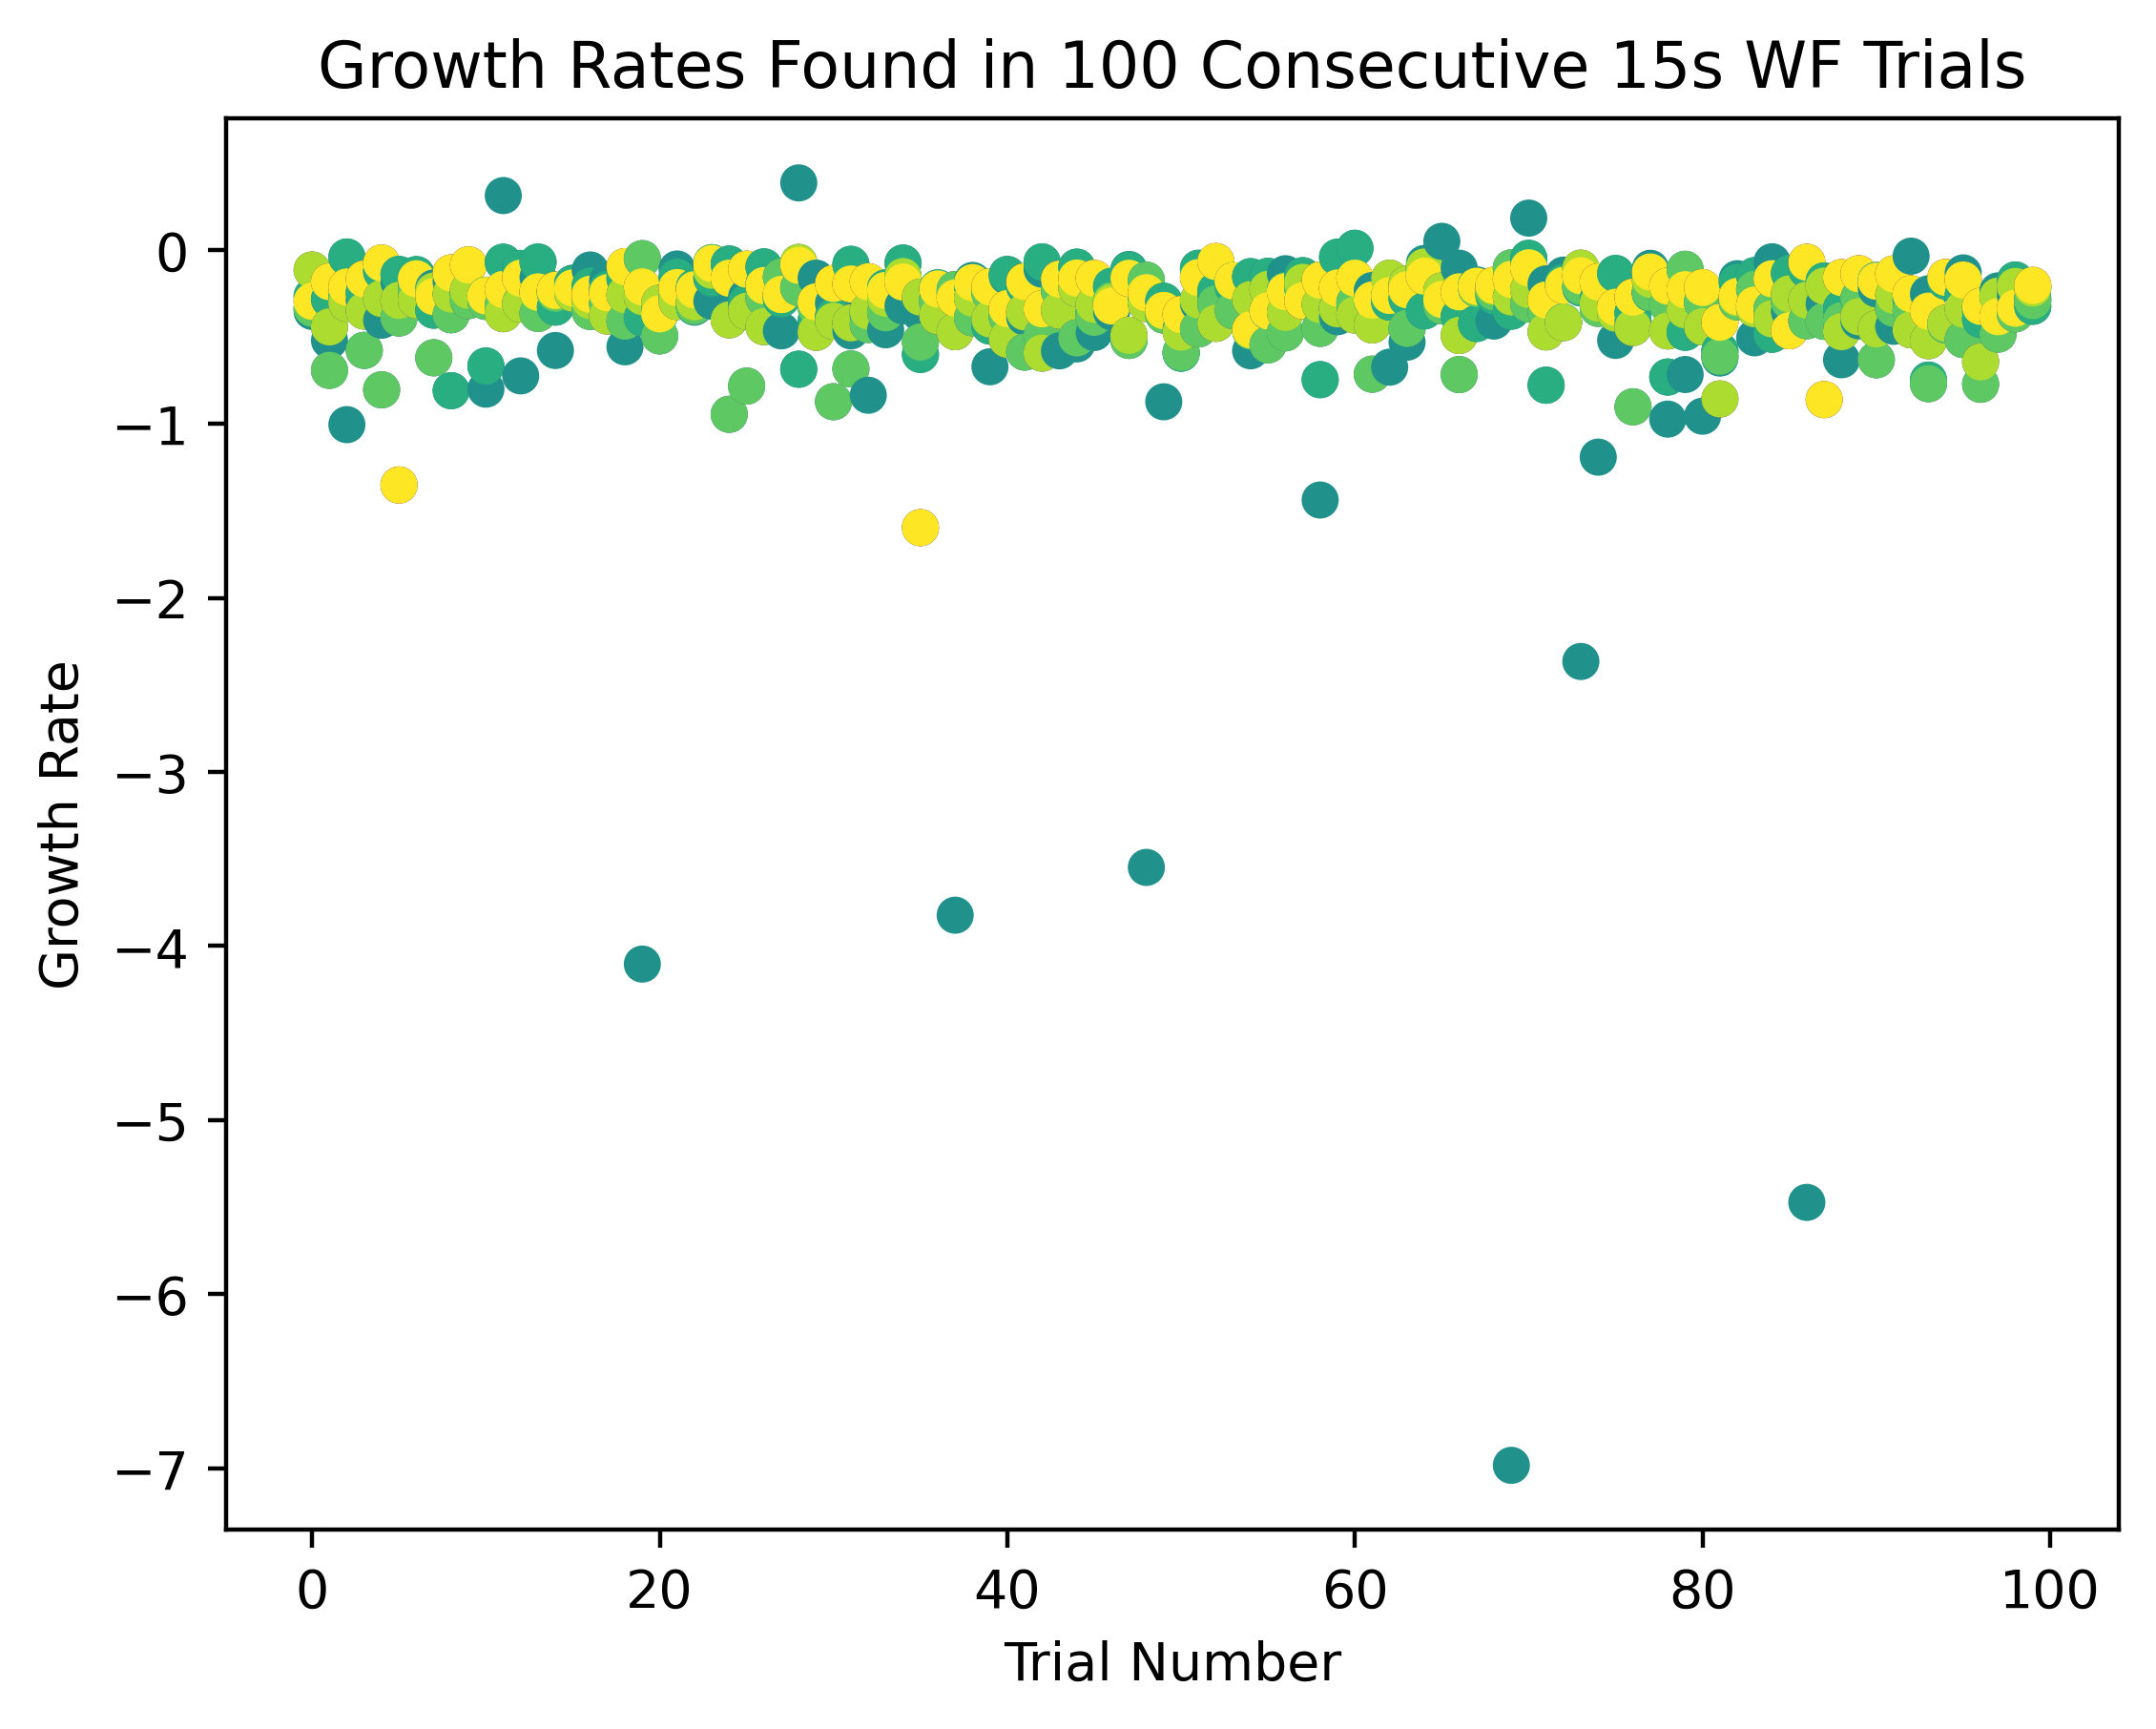

In [52]:
growth_rates = np.zeros((100,k))
for n in range(100):
    growth_rates[n] = np.real(np.log(eigs[n]))/0.0285
    plt.scatter(n*np.ones(k),growth_rates[n],c=np.arange(k))
    plt.ylabel("Growth Rate")
    plt.xlabel("Trial Number")
    plt.title("Growth Rates Found in 100 Consecutive 15s WF Trials")
plt.show()

So we see:

    Frequencies fall into non-overlapping bands: possibly equal to some constant value + noise
    Growth  rates seem to be about -0.1 + noise: possibly biased towards decaying. Some outliers

Overall fairly consistent with $D$ being constant + noise. For a control we'll compare to the eigenvalues/eigenvectors of random matrices and to random nearly orthogonal matrices. We will take 'nearly orthogonal' to mean orthogonal plus a small perturbation. The nearly orthogonal part comes from the fact that the matrix $A$ in HankelDMD is nearly orthogonal.

In [53]:
random_eigs = np.zeros((100,k),dtype='complex128')
random_evecs = np.zeros((100,k,k),dtype='complex128')
random_eigs_ortho = np.zeros((100,k),dtype='complex128')
random_evecs_ortho = np.zeros((100,k,k),dtype='complex128')
for n in tqdm(range(100)):
    random_mat = np.random.rand(k,k)
    eigs_random,evecs_random = np.linalg.eig(random_mat)
    eig_sort_idx_random = np.argsort(np.imag(np.log(eigs_random)))
    random_eigs[n] = eigs_random[eig_sort_idx_random]
    random_evecs[n] = evecs_random[:,eig_sort_idx_random]
    
    q,_ = np.linalg.qr(random_mat)
    q += 0.02*np.random.rand(k,k)
    eigs_random_ortho,evecs_random_ortho = np.linalg.eig(q)
    eig_sort_idx_random_ortho = np.argsort(np.imag(np.log(eigs_random_ortho)))
    random_eigs_ortho[n] = eigs_random_ortho[eig_sort_idx_random_ortho]
    random_evecs_ortho[n] = evecs_random_ortho[:,eig_sort_idx_random_ortho]

  0%|          | 0/100 [00:00<?, ?it/s]

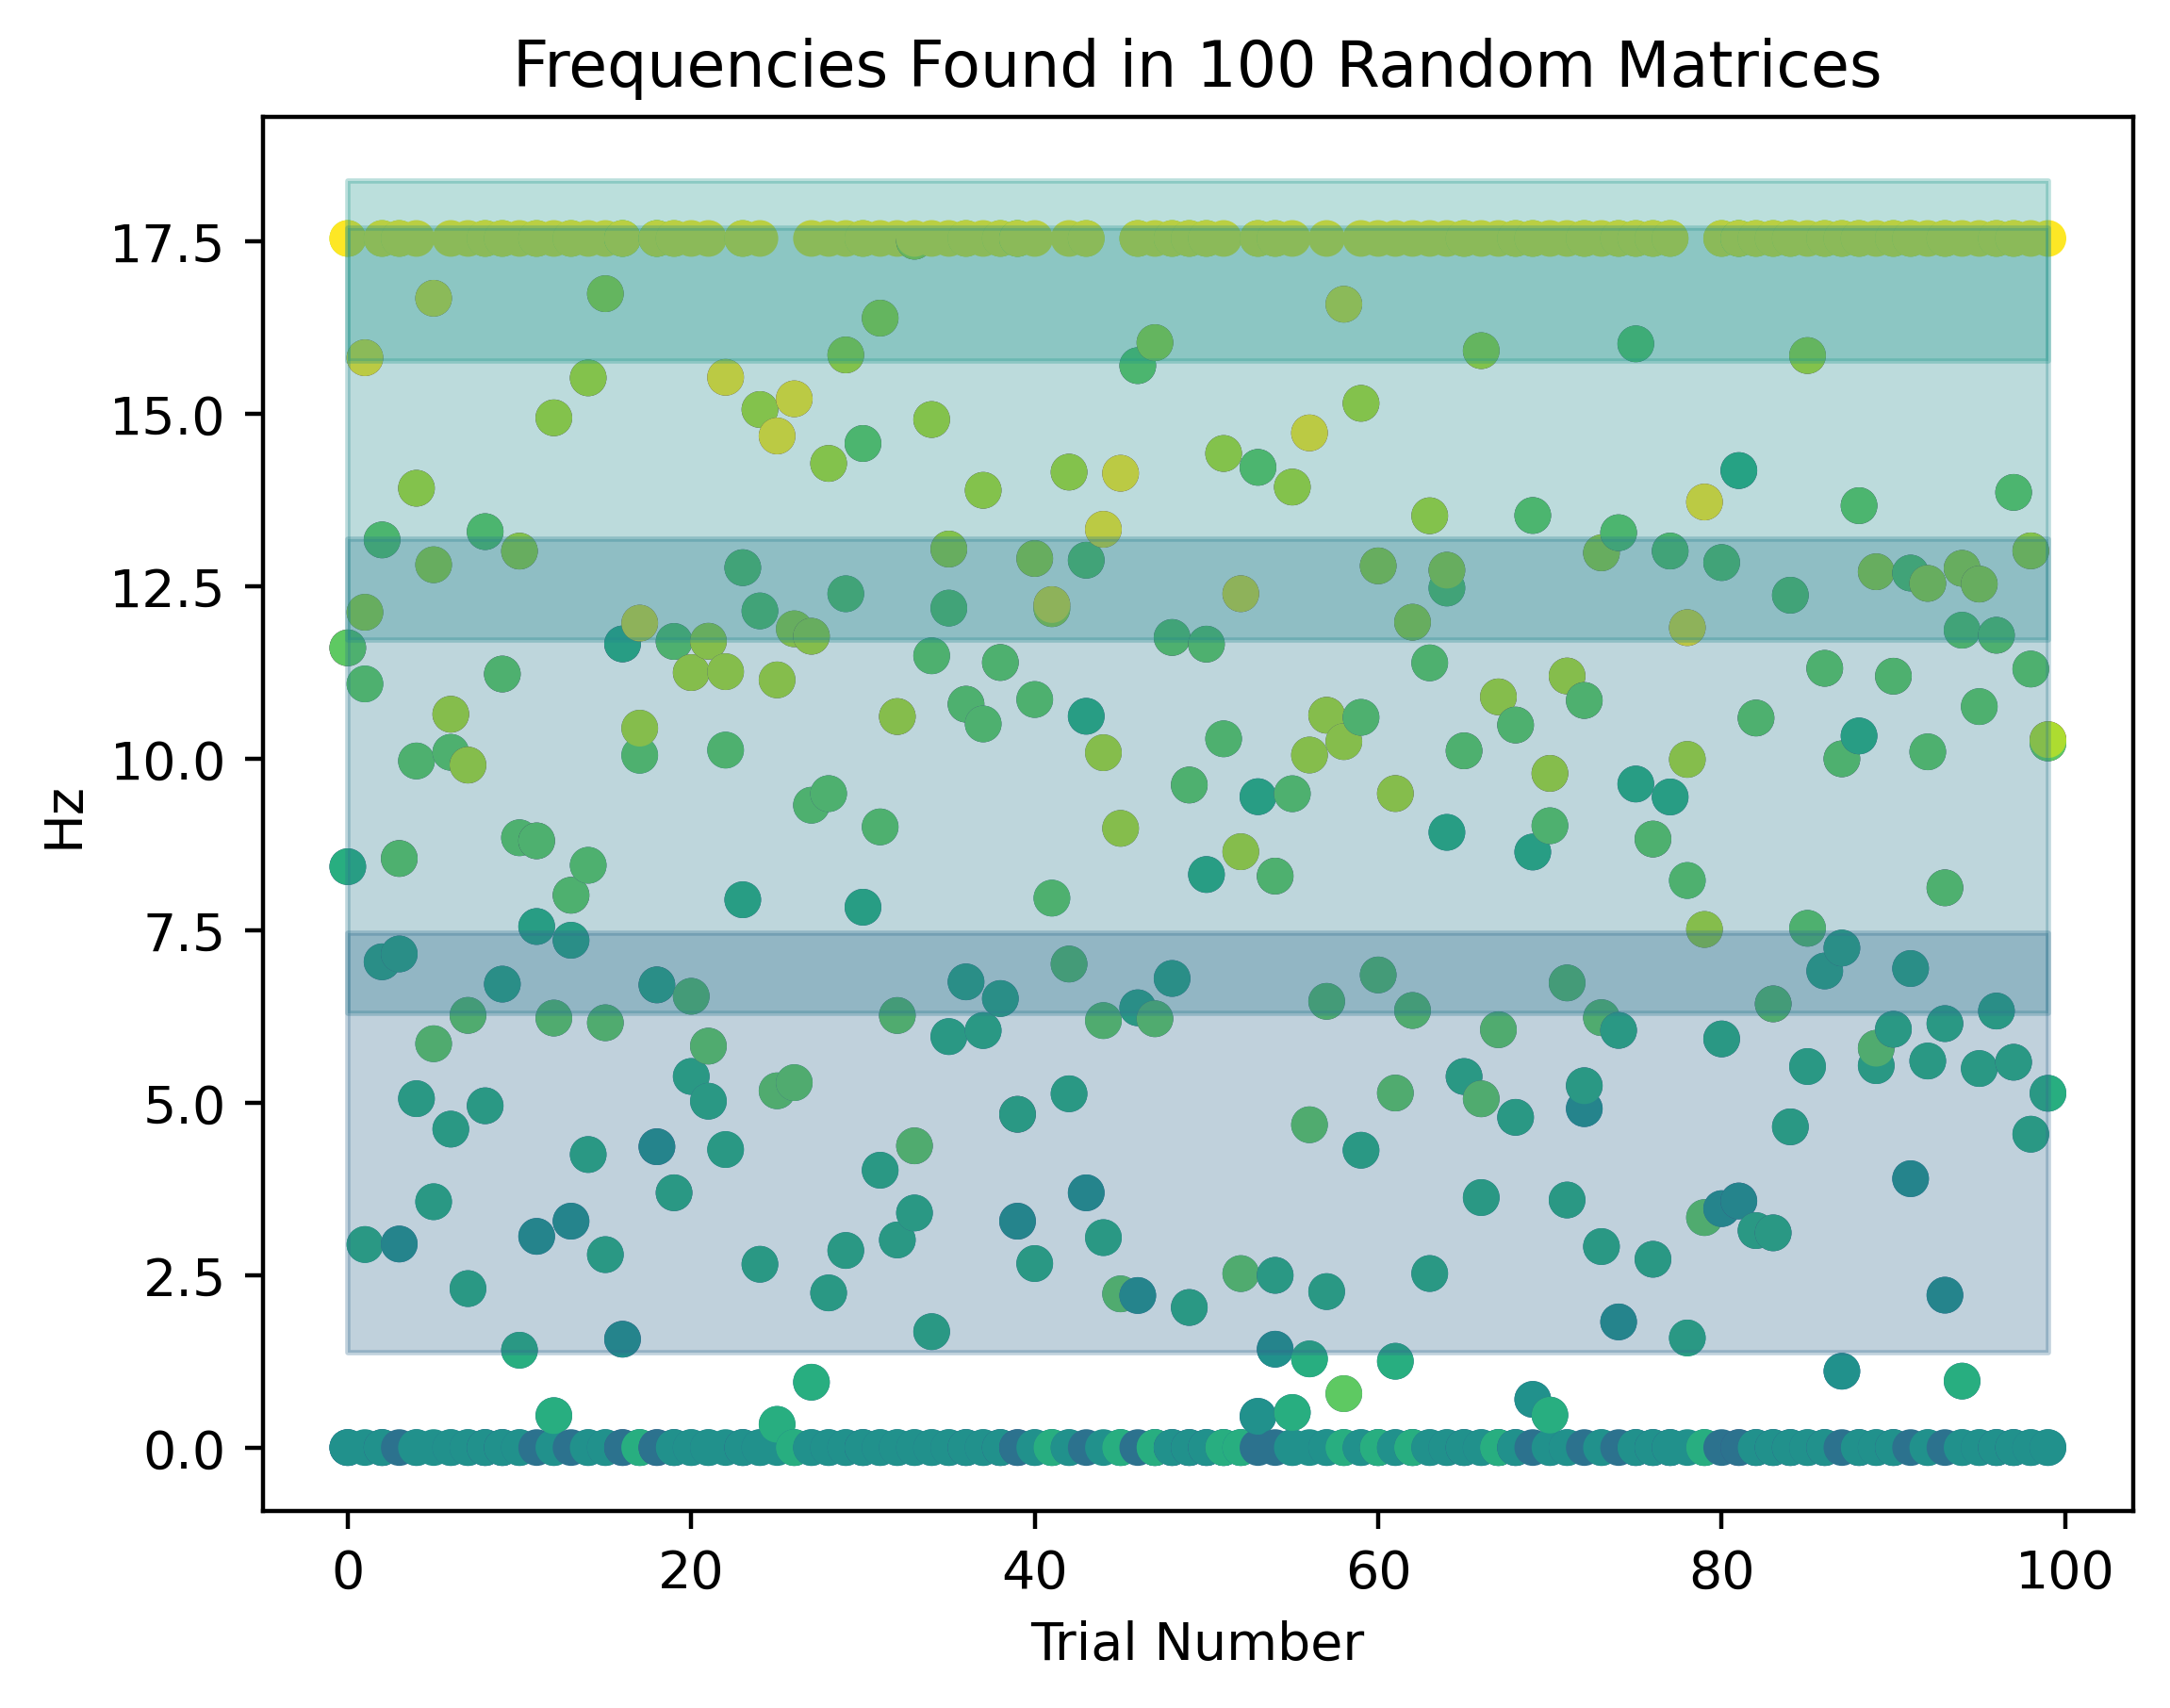

In [54]:
freqs_random = np.zeros((100,k))
for n in range(100):
    freqs_random[n] = np.imag(np.log(random_eigs[n]))/(2*np.pi*0.0285)
    plt.scatter(n*np.ones(k),np.abs(freqs_random[n]),c=np.arange(k))
    plt.ylabel("Hz")
    plt.xlabel("Trial Number")
    plt.title("Frequencies Found in 100 Random Matrices")
mean_freqs_random = np.mean(freqs_random,axis=0)
std_freqs_random = np.std(freqs_random,axis=0)
i = k-1
for i in range(k//2+1,k):
    #plt.axhline(np.abs(mean_freqs_random[i]))
    plt.fill_between(np.arange(100),np.abs(mean_freqs_random[i]-std_freqs_random[i]),np.abs(mean_freqs_random[i]+std_freqs_random[i]),alpha=0.3,color=cm.viridis(i/15)[:3])
plt.show()

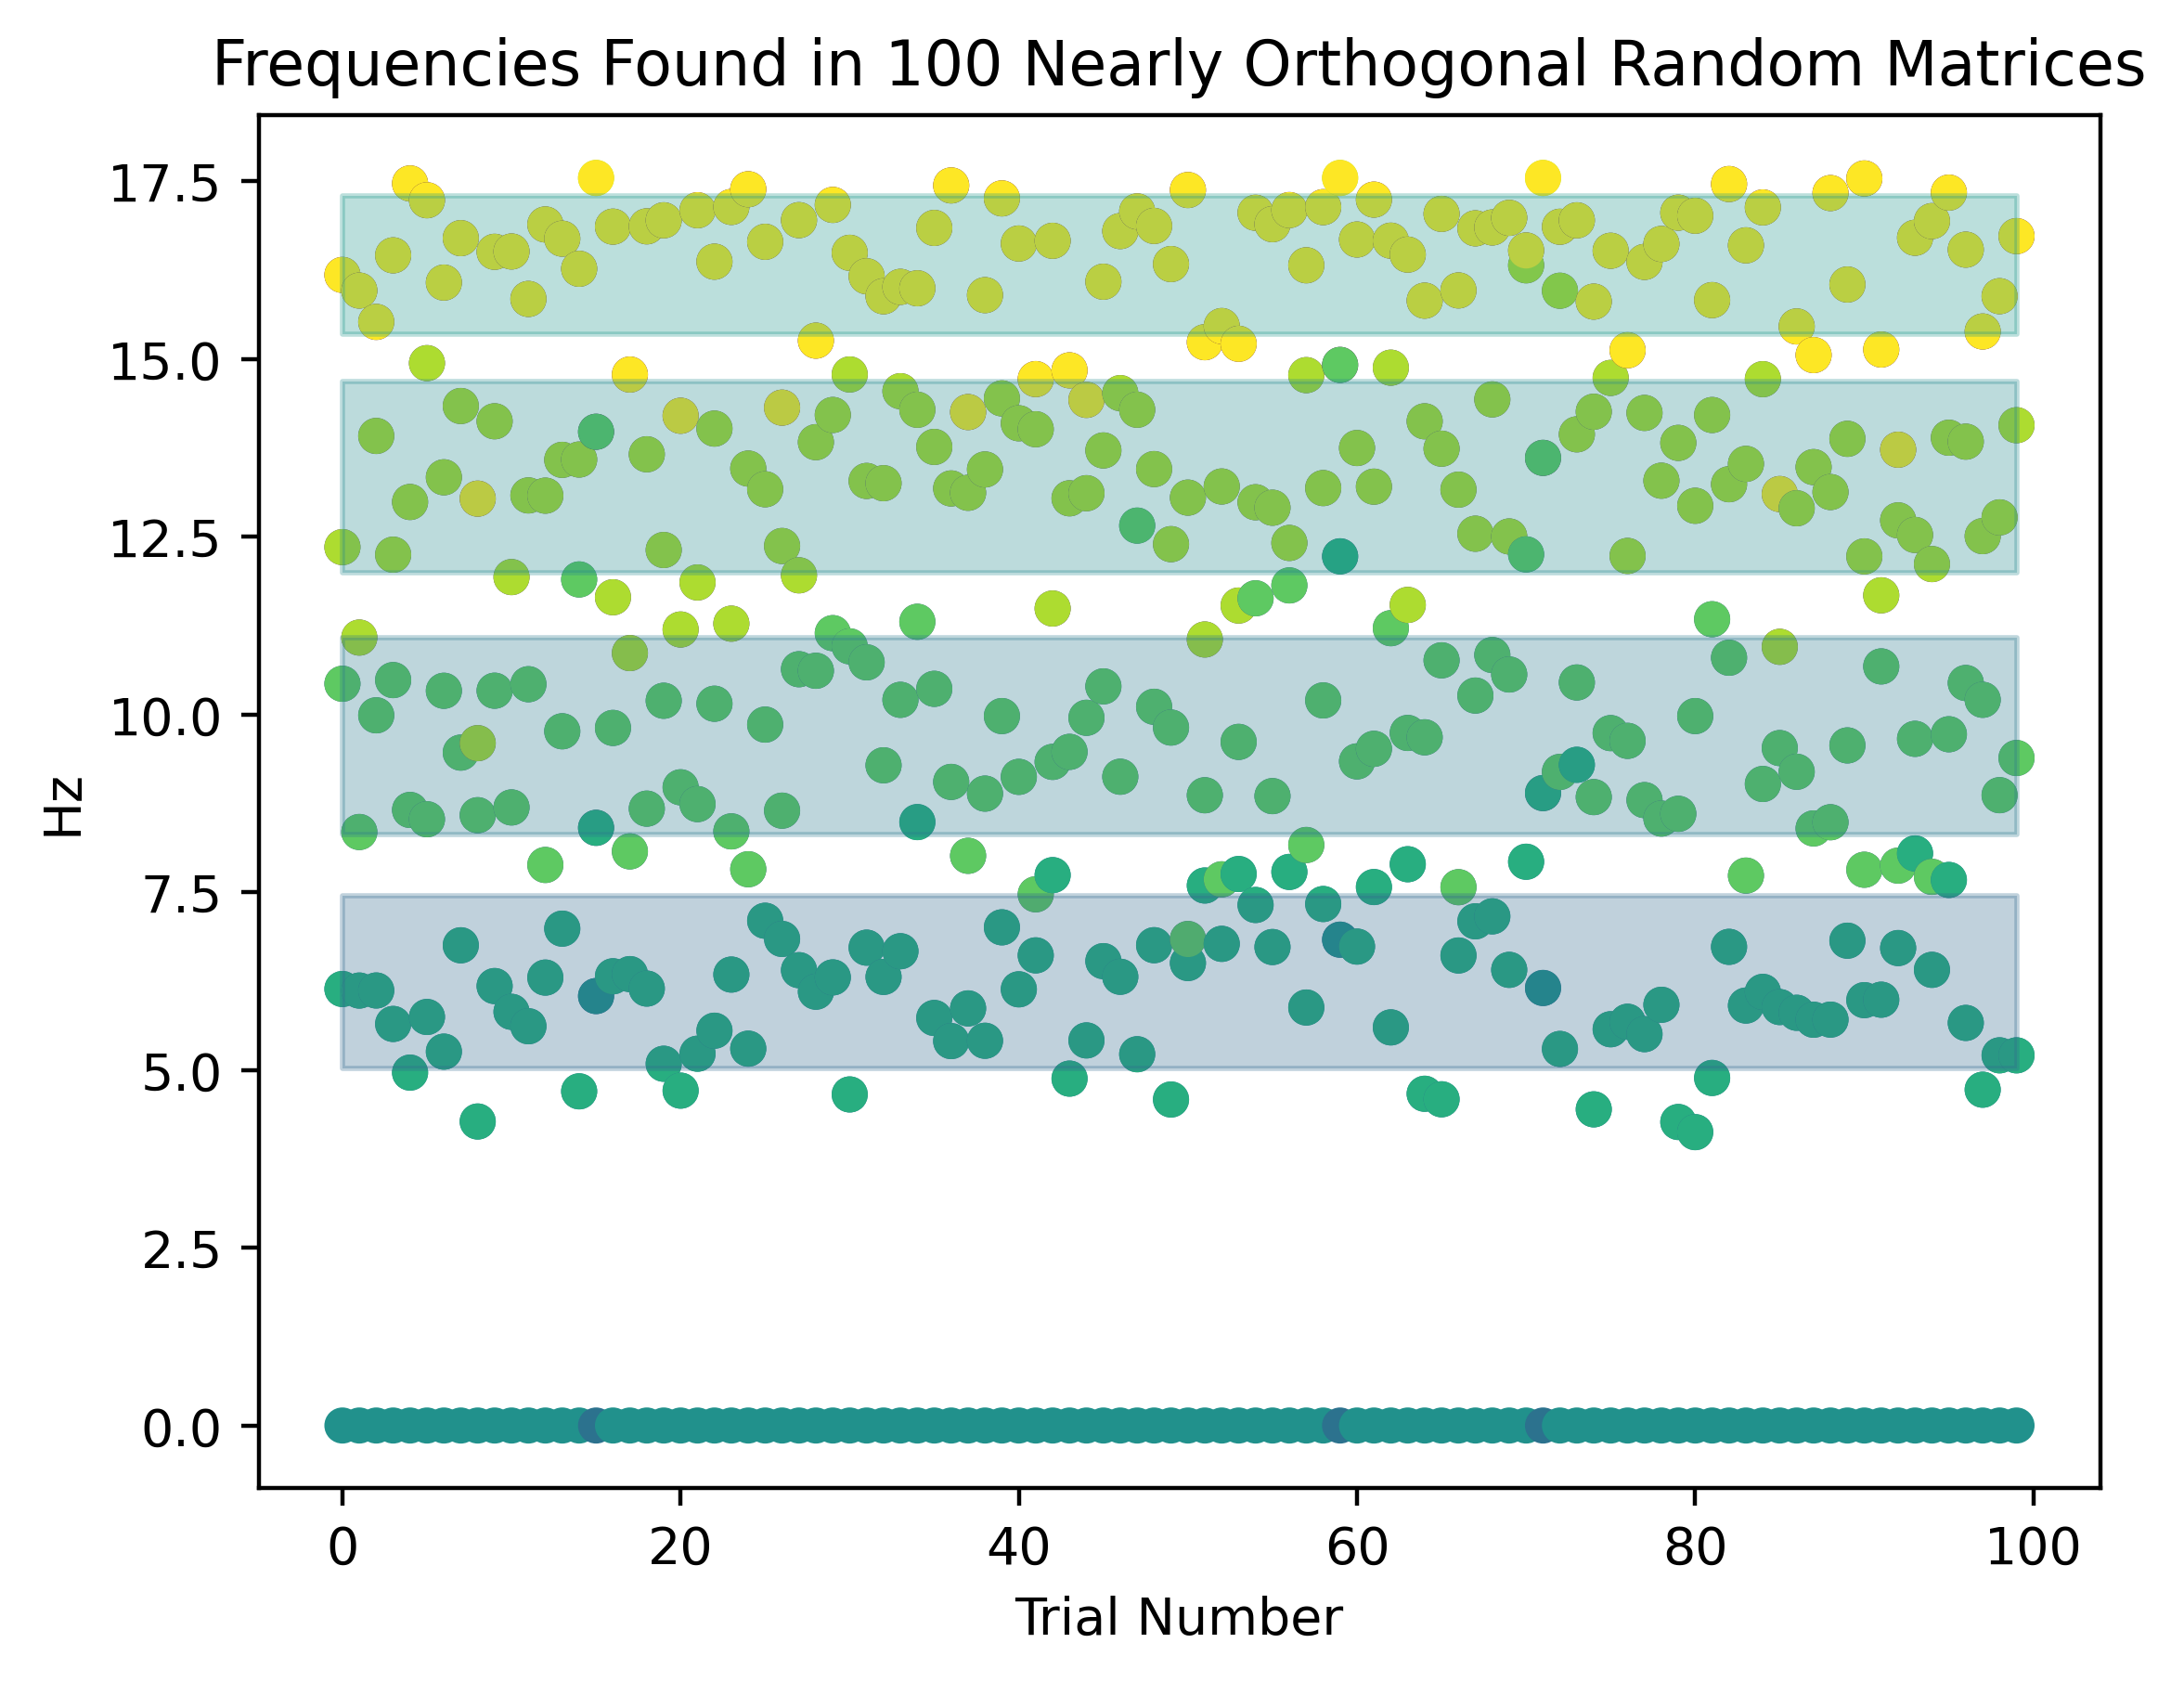

In [55]:
freqs_random_ortho = np.zeros((100,k))
for n in range(100):
    freqs_random_ortho[n] = np.imag(np.log(random_eigs_ortho[n]))/(2*np.pi*0.0285)
    plt.scatter(n*np.ones(k),np.abs(freqs_random_ortho[n]),c=np.arange(k))
    plt.ylabel("Hz")
    plt.xlabel("Trial Number")
    plt.title("Frequencies Found in 100 Nearly Orthogonal Random Matrices")
mean_freqs_random_ortho = np.mean(freqs_random_ortho,axis=0)
std_freqs_random_ortho = np.std(freqs_random_ortho,axis=0)
i = k-1
for i in range(k//2+1,k):
    #plt.axhline(np.abs(mean_freqs_random[i]))
    plt.fill_between(np.arange(100),np.abs(mean_freqs_random_ortho[i]-std_freqs_random_ortho[i]),np.abs(mean_freqs_random_ortho[i]+std_freqs_random_ortho[i]),alpha=0.3,color=cm.viridis(i/15)[:3])
plt.show()

It seems that generic random matrices do not form bands, but random nearly orthogonal matrices do.

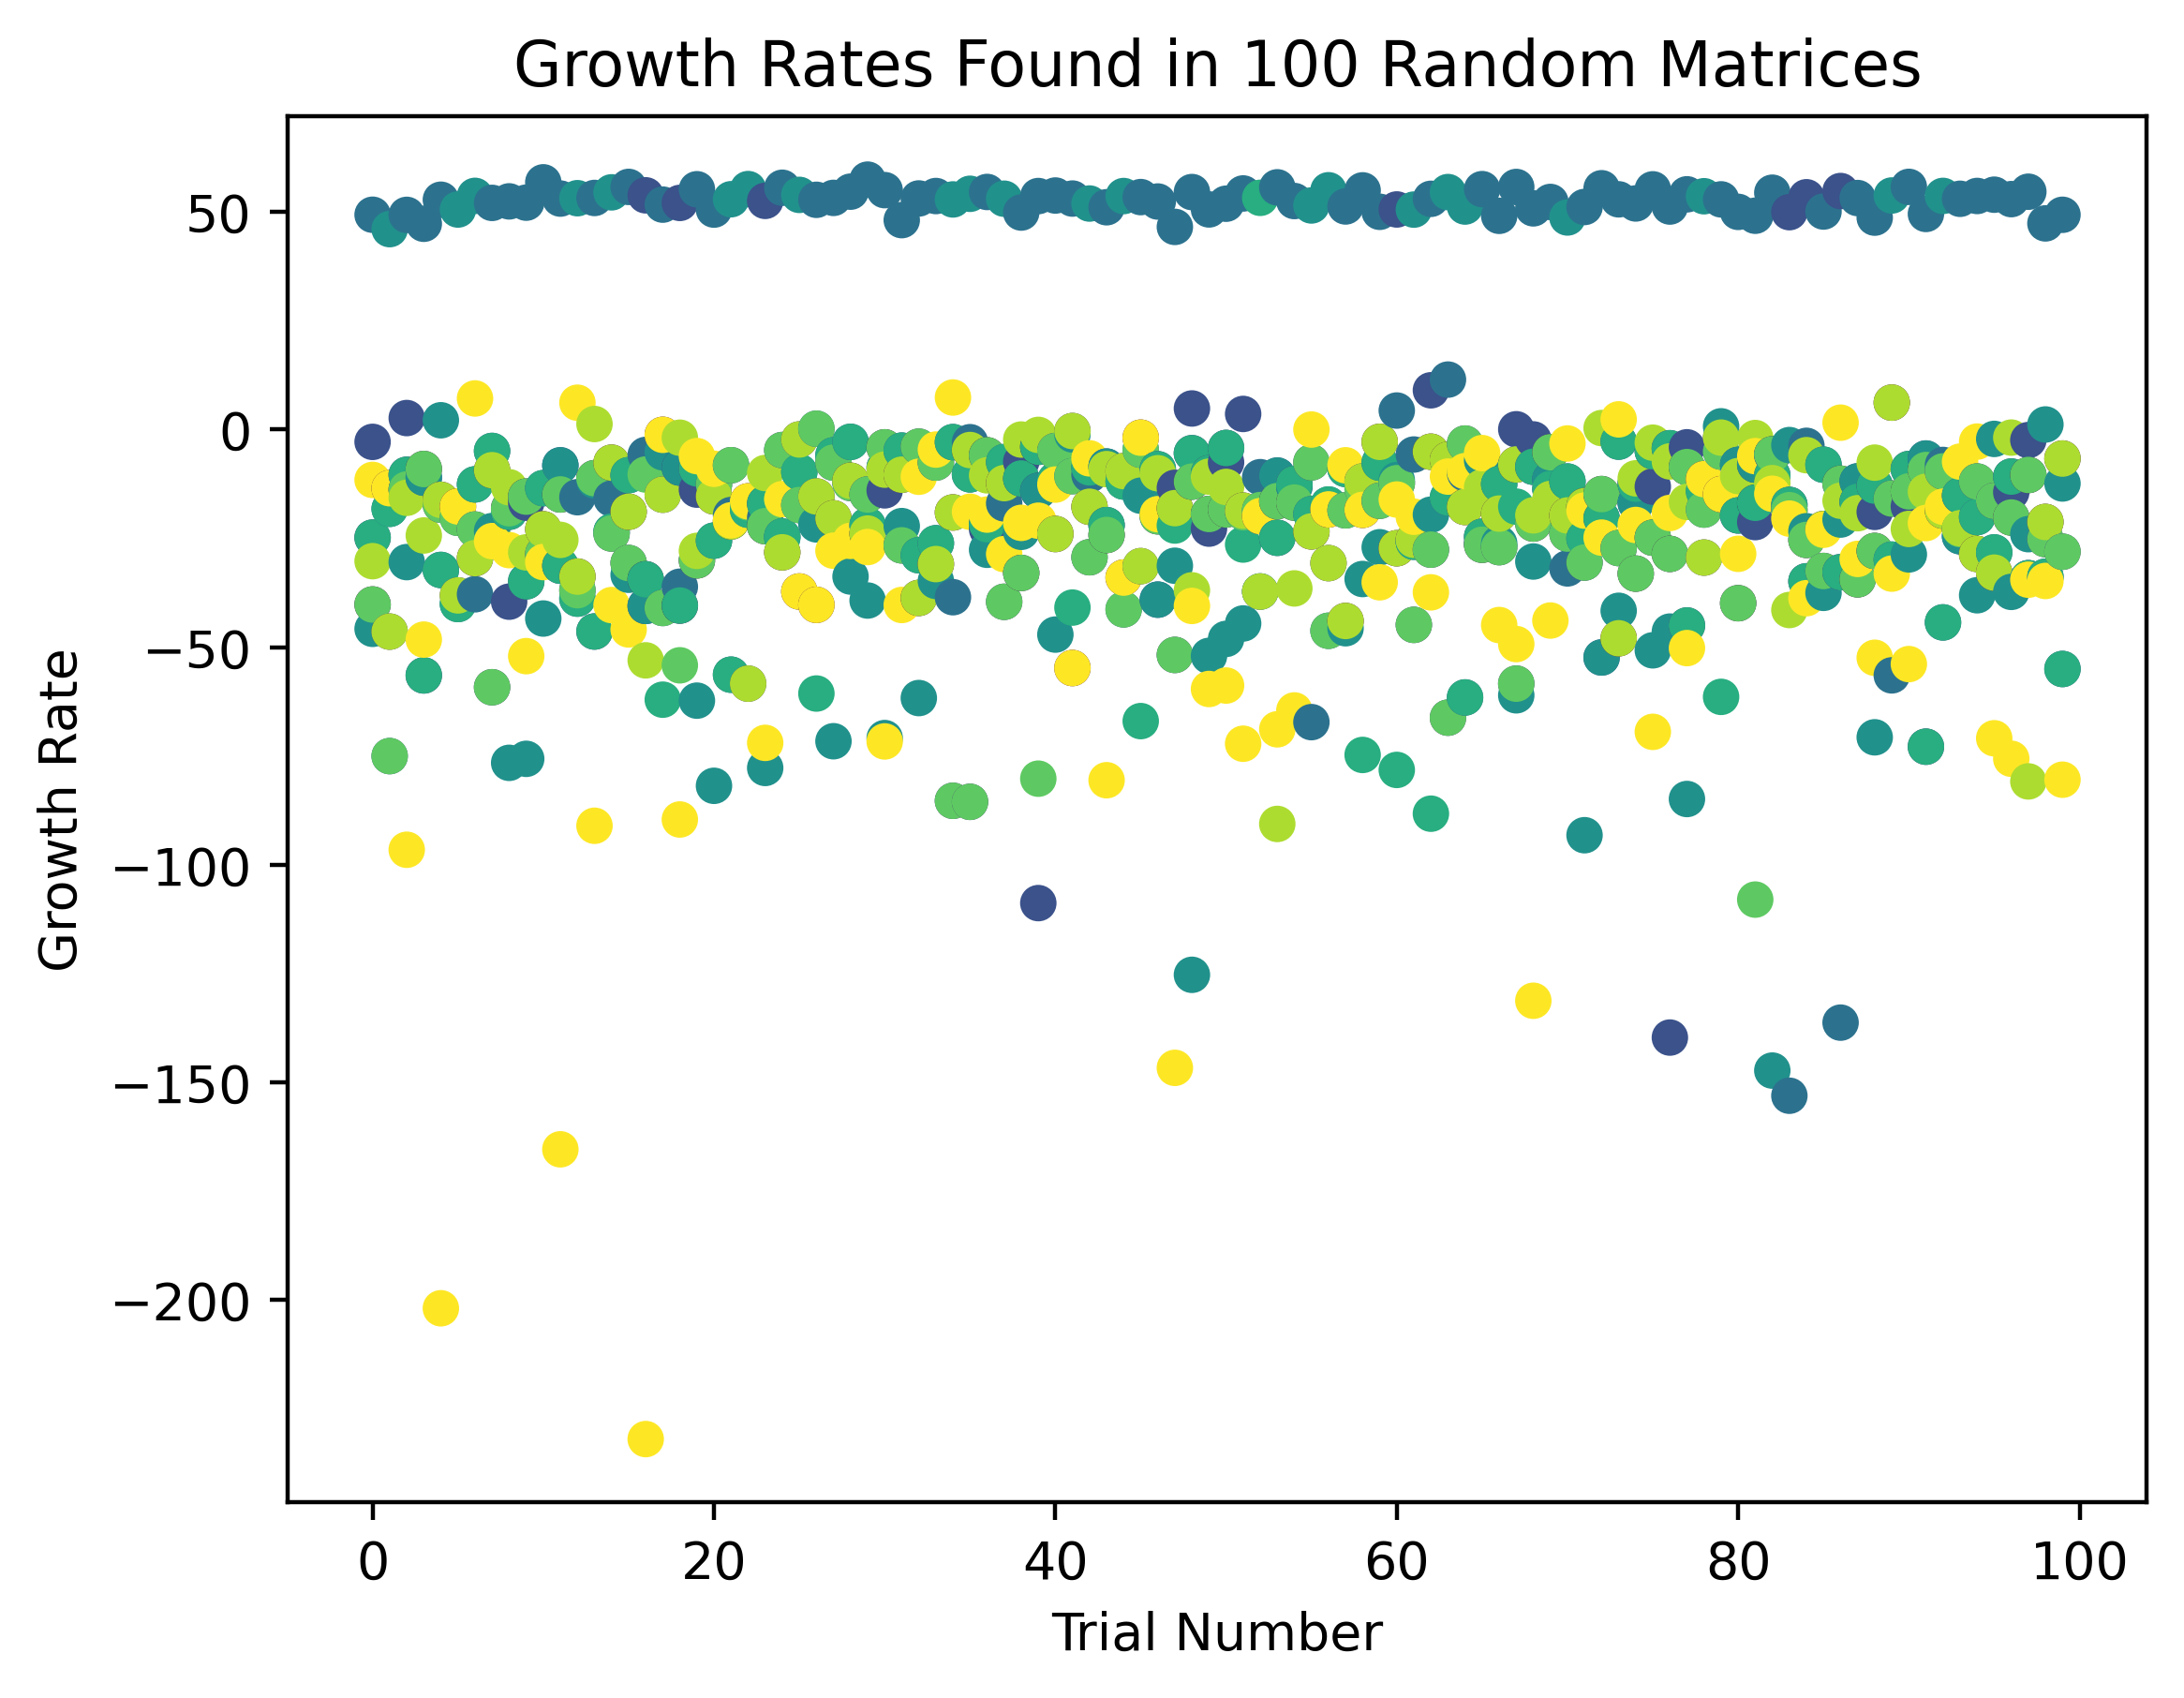

In [56]:
growth_rates = np.zeros((100,k))
for n in range(100):
    growth_rates[n] = np.real(np.log(random_eigs[n]))/0.0285
    plt.scatter(n*np.ones(k),growth_rates[n],c=np.arange(k))
    plt.ylabel("Growth Rate")
    plt.xlabel("Trial Number")
    plt.title("Growth Rates Found in 100 Random Matrices")
plt.show()

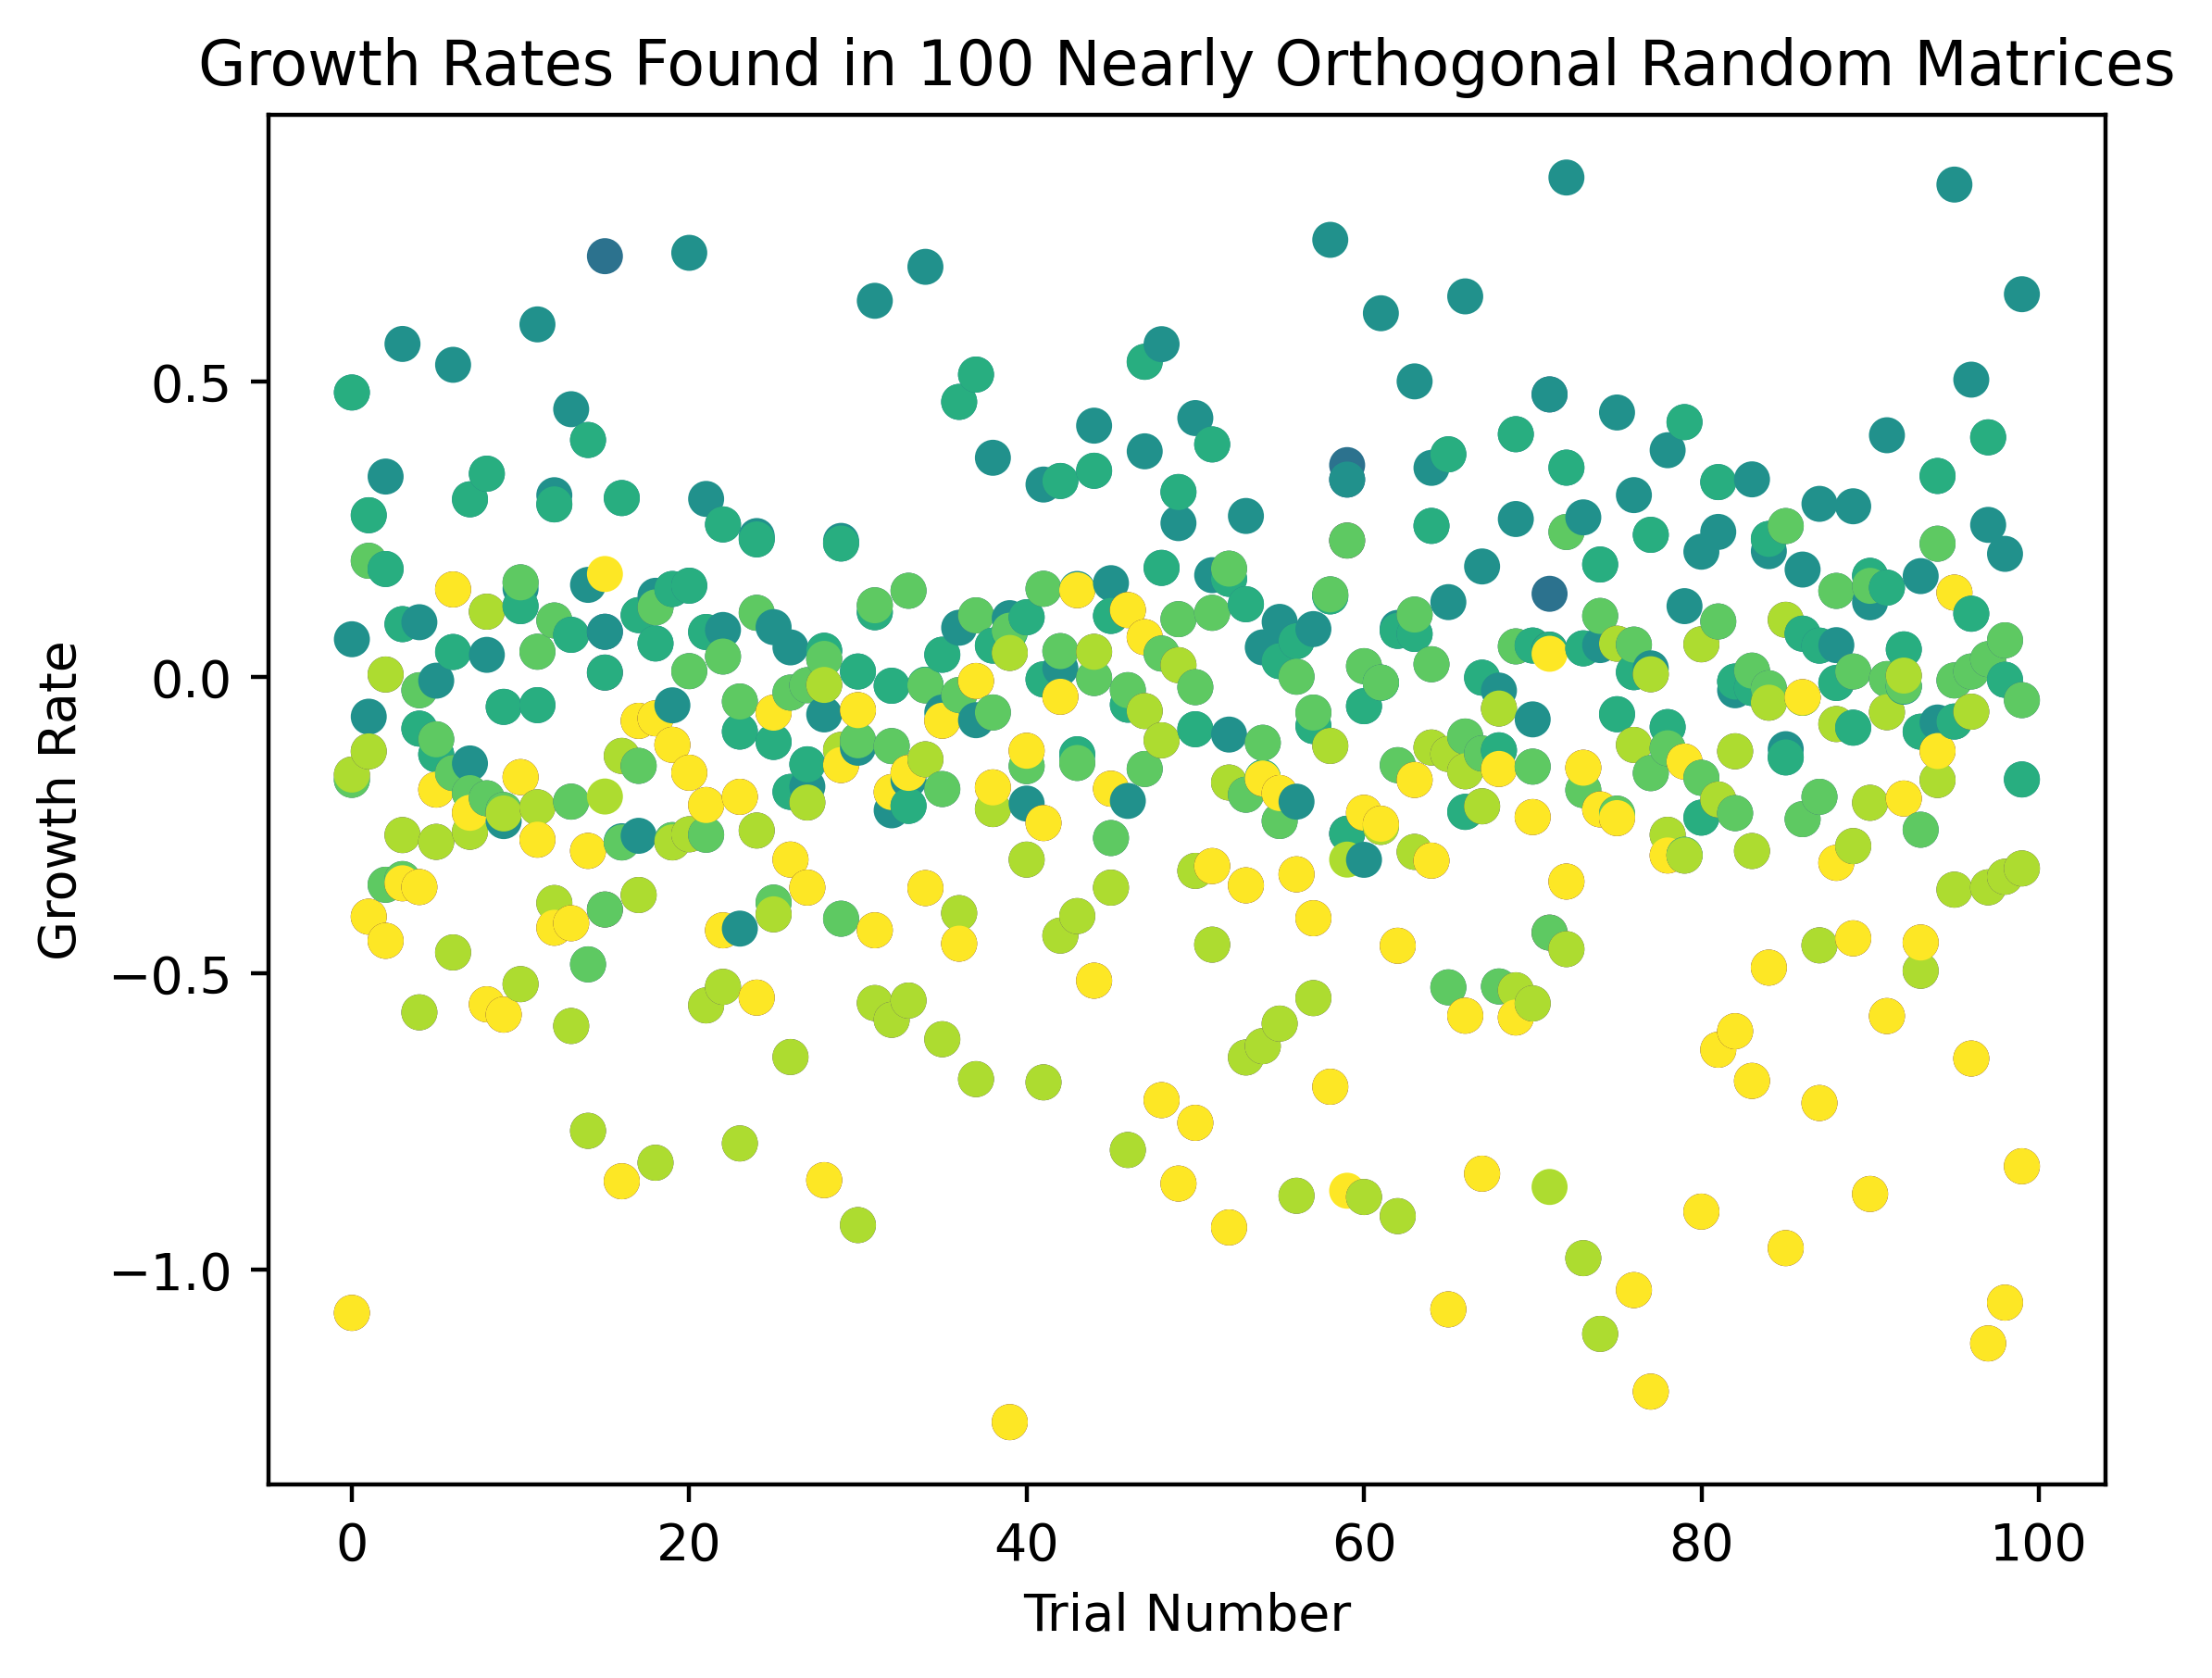

In [57]:
growth_rates = np.zeros((100,k))
for n in range(100):
    growth_rates[n] = np.real(np.log(random_eigs_ortho[n]))/0.0285
    plt.scatter(n*np.ones(k),growth_rates[n],c=np.arange(k))
    plt.ylabel("Growth Rate")
    plt.xlabel("Trial Number")
    plt.title("Growth Rates Found in 100 Nearly Orthogonal Random Matrices")
plt.show()

# Eigenvectors Related by Rotation Matrices

To measure how "close" a matrix is to being a rotation matrix, we can use two metrics together:

1. The distance between the matrix and the nearest orthogonal matrix (i.e. Frobenius norm of the difference). The nearest orthogonal matrix (in the sense of minimizing both the Frobenius norm and two-norm of the difference) is known to be the matrix $U$ in the polar decomposition $A=UP$. This tells us how close the matrix is to being orthogonal.
2. The determinant. Real orthogonal matrices with determinant 1 are precisely the rotation matrices; real orthogonal matrices with determinant -1 are precisely the reflection matrices.

For a control we'll do the complete process with eigenvectors of the random and random nearly orthogonal matrices as well.

In [58]:
def compute_metrics(matrices):
    dists = np.zeros((100,100))
    dets = np.zeros((100,100),dtype='complex128')
    for i in range(100):
        for j in range(100):
            R_ij = matrices[i]@np.linalg.inv(matrices[j])
            U,_ = polar(R_ij)
            dists[i,j] = np.linalg.norm(R_ij-U)
            dets[i,j] = np.linalg.det(R_ij)
    return dists,dets

In [59]:
true_dists,true_dets = compute_metrics(evecs)

In [60]:
print("Widefield data:")
print("Mean distance to nearest orthogonal matrix: " + str(np.mean(true_dists)))
print("Mean determinant of eigenvector transition matrix: " + str(np.mean(true_dets)))
print("Mean determinant of eigenvector transition matrix (absolute value): " + str(np.mean(np.abs(true_dets))))

Widefield data:
Mean distance to nearest orthogonal matrix: 1.6277880416981325
Mean determinant of eigenvector transition matrix: (0.047853175937988816+8.090440775913031e-18j)
Mean determinant of eigenvector transition matrix (absolute value): 1.427575638988059


In [61]:
random_dists,random_dets = compute_metrics(random_evecs)

In [62]:
print("Random Matrices:")
print("Mean distance to nearest orthogonal matrix: " + str(np.mean(random_dists)))
print("Mean determinant of eigenvector transition matrix: " + str(np.mean(random_dets)))
print("Mean determinant of eigenvector transition matrix (absolute value): " + str(np.mean(np.abs(random_dets))))

Random Matrices:
Mean distance to nearest orthogonal matrix: 6.102933402156811
Mean determinant of eigenvector transition matrix: (-0.1291927600544735-0.09927637599007146j)
Mean determinant of eigenvector transition matrix (absolute value): 3.3131714294625585


In [63]:
random_dists_ortho,random_dets_ortho = compute_metrics(random_evecs_ortho)

In [64]:
print("Random nearly orthogonal matrices:")
print("Mean distance to nearest orthogonal matrix: " + str(np.mean(random_dists_ortho)))
print("Mean determinant of eigenvector transition matrix: " + str(np.mean(random_dets_ortho)))
print("Mean determinant of eigenvector transition matrix (absolute value): " + str(np.mean(np.abs(random_dets_ortho))))

Random nearly orthogonal matrices:
Mean distance to nearest orthogonal matrix: 0.5654430368738637
Mean determinant of eigenvector transition matrix: (-0.006272300552028115-0.0009190598217394423j)
Mean determinant of eigenvector transition matrix (absolute value): 1.2217752606427559


By these metrics the matrices $R_{ij}$ from the original data are further from rotation matrices than the ones obtained from random nearly orthogonal matrices but closer than the ones obtained from random matrices. They are not rotation matrices are on average, but rather have negative determinant about half of the time. Overall to me it doesn't seem like there is more going on here than each $A_i$ being nearly orthogonal (though maybe not as nearly orthogonal as this control).